# Palmer Penguins: species classifier with boosting
**Goal:** predict the penguin species (Adelie, Chinstrap, Gentoo) from body measurements, island and sex.
**Data:** 344 penguins, 7 columns, in data/raw.
**Rules:** split first, every learned step lives inside a Pipeline, the test set stays locked until the end.

In [19]:
import pandas as pd 
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("../data/raw/penguins.csv")
df.head(5)

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,Male
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,Female
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,Female
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,Female


In [20]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    str    
 1   island             344 non-null    str    
 2   bill_length_mm     342 non-null    float64
 3   bill_depth_mm      342 non-null    float64
 4   flipper_length_mm  342 non-null    float64
 5   body_mass_g        342 non-null    float64
 6   sex                333 non-null    str    
dtypes: float64(4), str(3)
memory usage: 18.9 KB


In [21]:
df.columns 

Index(['species', 'island', 'bill_length_mm', 'bill_depth_mm',
       'flipper_length_mm', 'body_mass_g', 'sex'],
      dtype='str')

In [22]:
df.describe(include = "all")

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
count,344,344,342.000000,342.000000,342.000000,342.000000,333
unique,3,3,NaN,NaN,NaN,NaN,2
top,Adelie,Biscoe,NaN,NaN,NaN,NaN,Male
freq,152,168,NaN,NaN,NaN,NaN,168
mean,NaN,NaN,43.921930,17.151170,200.915205,4201.754386,NaN
std,NaN,NaN,5.459584,1.974793,14.061714,801.954536,NaN
min,NaN,NaN,32.100000,13.100000,172.000000,2700.000000,NaN
25%,NaN,NaN,39.225000,15.600000,190.000000,3550.000000,NaN
50%,NaN,NaN,44.450000,17.300000,197.000000,4050.000000,NaN
75%,NaN,NaN,48.500000,18.700000,213.000000,4750.000000,NaN


In [23]:
print(df.isnull().sum())
print(df.isna().mean()*100)

species               0
island                0
bill_length_mm        2
bill_depth_mm         2
flipper_length_mm     2
body_mass_g           2
sex                  11
dtype: int64
species              0.000000
island               0.000000
bill_length_mm       0.581395
bill_depth_mm        0.581395
flipper_length_mm    0.581395
body_mass_g          0.581395
sex                  3.197674
dtype: float64


In [24]:
missing = df.isnull().sum().sort_values(ascending = False)
print(missing[missing > 0])


sex                  11
bill_depth_mm         2
bill_length_mm        2
flipper_length_mm     2
body_mass_g           2
dtype: int64


In [25]:
df.shape

(344, 7)

## 2. First look
**Goal:** check shape, types, missing values and class balance before any change.
**Finding:** 344 penguins, 3 species (Adelie 152, Gentoo 124, Chinstrap 68). Missing: sex 11, each body measurement 2 (11 rows in total). Scales differ a lot (body_mass_g std about 800, bill_depth_mm about 2). No impossible values.
**Decision:** keep the missing rows and impute inside the Pipeline. Do EDA on the train part only.

In [26]:
from sklearn.model_selection import train_test_split

X = df.drop(columns = "species")
y = df["species"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print(X_train.shape,y_train.shape)
print(X_test.shape,y_test.shape)
print(y_train.value_counts(normalize=True))
print(y_test.value_counts(normalize=True))


(275, 6) (275,)
(69, 6) (69,)
species
Adelie       0.443636
Gentoo       0.360000
Chinstrap    0.196364
Name: proportion, dtype: float64
species
Adelie       0.434783
Gentoo       0.362319
Chinstrap    0.202899
Name: proportion, dtype: float64


## 4. EDA on the train set only
**Goal:** see how the species differ before we build any model.
**Finding:** ___
**Decision:** ___

In [27]:
numeric_cols = ["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]
categorical_cols = ["island", "sex"]

train = X_train.copy()
train["species"] = y_train

print(train.groupby("species")[numeric_cols].mean().round(1))
print(pd.crosstab(train["species"], train["island"]))

           bill_length_mm  bill_depth_mm  flipper_length_mm  body_mass_g
species                                                                 
Adelie               38.9           18.4              189.7       3705.4
Chinstrap            49.0           18.5              196.6       3761.1
Gentoo               47.7           14.9              217.0       5083.9
island     Biscoe  Dream  Torgersen
species                            
Adelie         35     44         43
Chinstrap       0     54          0
Gentoo         99      0          0


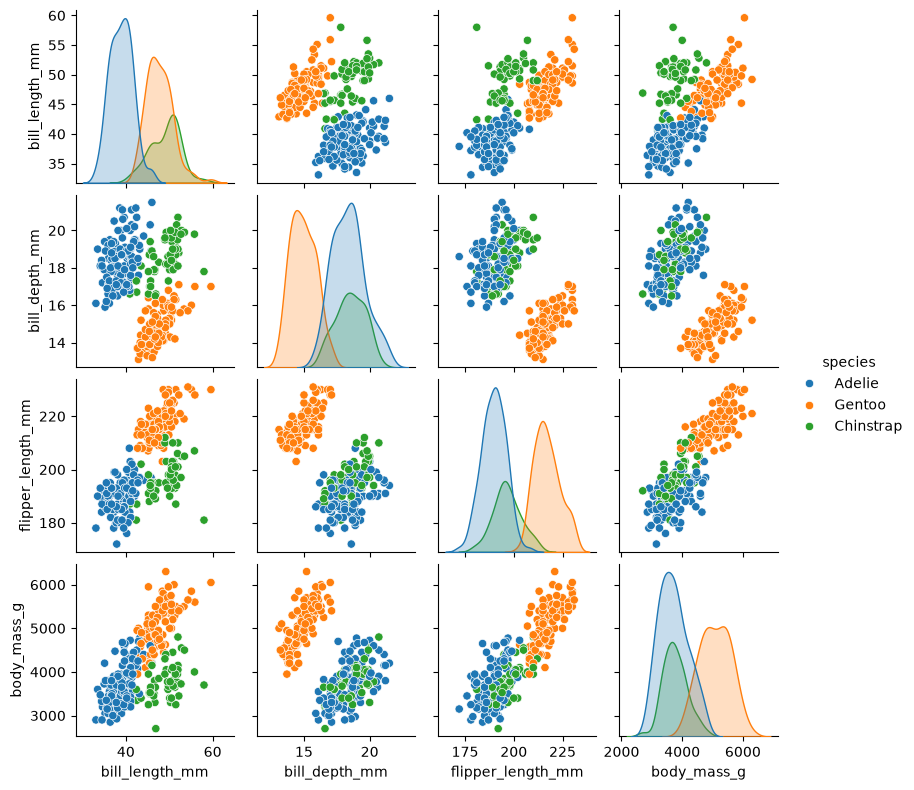

In [28]:
sns.pairplot(train, vars=numeric_cols, hue="species", height=2)
plt.show()

In [29]:

num_cols = ['bill_length_mm', 'bill_depth_mm','flipper_length_mm', 'body_mass_g']

cat_cols = ['sex', 'island']

In [30]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder , StandardScaler
from sklearn.pipeline import Pipeline

num_pipe = Pipeline([
    ("impute",SimpleImputer(strategy='median')),
    ("scaler", StandardScaler())
])

cat_pipe = Pipeline([
    ("impute",SimpleImputer(strategy='most_frequent')),
    ("onehot", OneHotEncoder(handle_unknown='ignore'))
])

print(num_pipe,"\n\n",cat_pipe)


Pipeline(steps=[('impute', SimpleImputer(strategy='median')),
                ('scaler', StandardScaler())]) 

 Pipeline(steps=[('impute', SimpleImputer(strategy='most_frequent')),
                ('onehot', OneHotEncoder(handle_unknown='ignore'))])


In [31]:
num_pipe

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('impute', ...), ('scaler', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"strategy strategy: str or Callable, default='mean'The imputation strategy.- If ""mean"", then replace missing values using the mean along each column. Can only be used with numeric data.- If ""median"", then replace missing values using the median along each column. Can only be used with numeric data.- If ""most_frequent"", then replace missing using the most frequent value along each column. Can be used with strings or numeric data. If there is more than one such value, only the smallest is returned.- If ""constant"", then replace missing values with fill_value. Can be used with strings or numeric data.- If an instance of Callable, then replace missing values using the scalar statistic returned by running the callable over a dense 1d array containing non-missing values of each column... versionadded:: 0.20 strategy=""constant"" for fixed value imputation... versionadded:: 1.5 strategy=callable for custom value imputation.",'median'
,"missing_values missing_values: int, float, str, np.nan, None or pandas.NA, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`can be set to either `np.nan` or `pd.NA`.",nan
,"fill_value fill_value: str or numerical value, default=NoneWhen strategy == ""constant"", `fill_value` is used to replace alloccurrences of missing_values. For string or object data types,`fill_value` must be a string.If `None`, `fill_value` will be 0 when imputing numericaldata and ""missing_value"" for strings or object data types.",None
,"copy copy: bool, default=TrueIf True, a copy of X will be created. If False, imputation willbe done in-place whenever possible. Note that, in the following cases,a new copy will always be made, even if `copy=False`:- If `X` is not an array of floating values;- If `X` is encoded as a CSR matrix;- If `add_indicator=True`.",True
,"add_indicator add_indicator: bool, default=FalseIf True, a :class:`MissingIndicator` transform will stack onto outputof the imputer's transform. This allows a predictive estimatorto account for

In [32]:
cat_pipe

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('impute', ...), ('onehot', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"strategy strategy: str or Callable, default='mean'The imputation strategy.- If ""mean"", then replace missing values using the mean along each column. Can only be used with numeric data.- If ""median"", then replace missing values using the median along each column. Can only be used with numeric data.- If ""most_frequent"", then replace missing using the most frequent value along each column. Can be used with strings or numeric data. If there is more than one such value, only the smallest is returned.- If ""constant"", then replace missing values with fill_value. Can be used with strings or numeric data.- If an instance of Callable, then replace missing values using the scalar statistic returned by running the callable over a dense 1d array containing non-missing values of each column... versionadded:: 0.20 strategy=""constant"" for fixed value imputation... versionadded:: 1.5 strategy=callable for custom value imputation.",'most_frequent'
,"missing_values missing_values: int, float, str, np.nan, None or pandas.NA, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`can be set to either `np.nan` or `pd.NA`.",nan
,"fill_value fill_value: str or numerical value, default=NoneWhen strategy == ""constant"", `fill_value` is used to replace alloccurrences of missing_values. For string or object data types,`fill_value` must be a string.If `None`, `fill_value` will be 0 when imputing numericaldata and ""missing_value"" for strings or object data types.",None
,"copy copy: bool, default=TrueIf True, a copy of X will be created. If False, imputation willbe done in-place whenever possible. Note that, in the following cases,a new copy will always be made, even if `copy=False`:- If `X` is not an array of floating values;- If `X` is encoded as a CSR matrix;- If `add_indicator=True`.",True
,"add_indicator add_indicator: bool, default=FalseIf True, a :class:`MissingIndicator` transform will stack onto outputof the imputer's transform. This allows a predictive estimatorto acco

## 4. EDA on the train set only
**Goal:** see how the species differ before we build any model.
**Finding:** Gentoo is clearly separated (smaller bill depth, longer flipper, heavier). Adelie and Chinstrap overlap on flipper and body mass but differ in bill length. No single column separates all three; bill_length with bill_depth gives three clear clusters. Gentoo lives only on Biscoe and Chinstrap only on Dream, so island is a shortcut risk.
**Decision:** use all measurements. Impute inside the pipeline (median for numbers, most_frequent for sex). Later, compare the model with and without island.

In [33]:
from sklearn.compose import ColumnTransformer

preprocessor = ColumnTransformer([
    ("numeric",num_pipe,num_cols),
    ("categorical",cat_pipe,cat_cols),
])
out = preprocessor.fit_transform(X_train,y_train)
print(out.shape)
print("NAN left:", pd.isna(out).sum())
print(preprocessor.get_feature_names_out())

(275, 9)
NAN left: 0
['numeric__bill_length_mm' 'numeric__bill_depth_mm'
 'numeric__flipper_length_mm' 'numeric__body_mass_g'
 'categorical__sex_Female' 'categorical__sex_Male'
 'categorical__island_Biscoe' 'categorical__island_Dream'
 'categorical__island_Torgersen']


## 5. Pipe
**Goal:** one preprocessor: numbers imputed and scaled, text imputed and one-hot encoded.
**Finding:** On train the preprocessor gives 275 rows x 9 columns (4 numeric + 2 sex + 3 island) and no empty cells.
**Decision:** keep the two recipes as they are. The preprocessor goes inside every Pipeline and is never applied to X_test by hand.

## 6. Baselines
**Goal:** find the score every real model must beat.
**Finding:** ___
**Decision:** ___

In [34]:
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.dummy import DummyClassifier
from sklearn.tree import DecisionTreeClassifier

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

baselines = {
    "Lazy (always Adelie)": DummyClassifier(strategy="most_frequent"),
    "One stump": DecisionTreeClassifier(max_depth=1, random_state=42),
}

for name, m in baselines.items():
    pipe = Pipeline([("prep", preprocessor), ("model", m)])
    s = cross_validate(pipe, X_train, y_train, cv=cv,
                       scoring=["accuracy", "recall_macro", "roc_auc_ovr"])
    print(name)
    for metric in ["accuracy", "recall_macro", "roc_auc_ovr"]:
        print("  ", metric, ":", s[f"test_{metric}"].mean().round(2))

Lazy (always Adelie)
   accuracy : 0.44
   recall_macro : 0.33
   roc_auc_ovr : 0.5
One stump
   accuracy : 0.79
   recall_macro : 0.65
   roc_auc_ovr : 0.82
